# Machine Failure Prediction from Sensor Data

**Goal:** predict whether an industrial machine will fail (`fail` = 1) based on
readings from nine onboard sensors (air quality, ultrasonic sensor, footfall,
temperature, etc.).

This is a binary classification problem. The notebook follows a standard
supervised-learning workflow:

1. Data understanding
2. Data quality checks
3. Train/test split
4. Exploratory data analysis (train set only)
5. Feature engineering
6. Model building & cross-validated comparison
7. Hyperparameter tuning
8. Final evaluation on the held-out test set
9. Model interpretation
10. Model persistence

**Dataset:** [Machine Failure Prediction Using Sensor Data](https://www.kaggle.com/datasets/umerrtx/machine-failure-prediction-using-sensor-data) (Kaggle).


## 1. Setup

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    cross_val_predict, RandomizedSearchCV
)
from sklearn.utils.validation import check_array
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    precision_recall_curve, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    average_precision_score
)
from scipy.stats import randint, uniform

%matplotlib inline
sns.set_style("whitegrid")

## 2. Data Understanding

The dataset is loaded from a local `data/` folder so the notebook runs
end-to-end without a Kaggle-specific environment. If you're running this
yourself, download `data.csv` from the Kaggle link above and place it at
`data/data.csv`.

In [25]:
DATA_PATH = Path("notebook\dataset\data.csv")
sensor_data = pd.read_csv(DATA_PATH)

<>:1: SyntaxWarning: invalid escape sequence '\d'
<>:1: SyntaxWarning: invalid escape sequence '\d'
C:\Users\Nima\AppData\Local\Temp\ipykernel_1576\2654208493.py:1: SyntaxWarning: invalid escape sequence '\d'
  DATA_PATH = Path("notebook\dataset\data.csv")


In [26]:
sensor_data = sensor_data.rename(columns={
                                        'footfall': 'footfall',                                        
                                        'tempMode': 'TempMode',
                                        'AQ': 'AirQuality',
                                        'USS': 'UltrSensData',
                                        'CS': 'CurSensRead',
                                        'VOC': 'VolatileOrgComp',
                                        'RP': 'RPM',
                                        'IP': 'InptPressure',
                                        'Temperature': 'OptTemp',
                                        'fail' : 'Failure'
                                        })

sensor_data.info()
sensor_data.head(3)


<class 'pandas.DataFrame'>
RangeIndex: 944 entries, 0 to 943
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   footfall         944 non-null    int64
 1   TempMode         944 non-null    int64
 2   AirQuality       944 non-null    int64
 3   UltrSensData     944 non-null    int64
 4   CurSensRead      944 non-null    int64
 5   VolatileOrgComp  944 non-null    int64
 6   RPM              944 non-null    int64
 7   InptPressure     944 non-null    int64
 8   OptTemp          944 non-null    int64
 9   Failure          944 non-null    int64
dtypes: int64(10)
memory usage: 73.9 KB


,footfall,TempMode,AirQuality,UltrSensData,CurSensRead,VolatileOrgComp,RPM,InptPressure,OptTemp,Failure
0,0,7,7,1,6,6,36,3,1,1
1,190,1,3,3,5,1,20,4,1,0
2,31,7,2,2,6,1,24,6,1,0


In [27]:
sensor_data.describe().T

,count,mean,std,min,25%,50%,75%,max
footfall,944.0,306.381356,1082.606745,0.0,1.0,22.0,110.0,7300.0
TempMode,944.0,3.727754,2.677235,0.0,1.0,3.0,7.0,7.0
AirQuality,944.0,4.325212,1.438436,1.0,3.0,4.0,6.0,7.0
UltrSensData,944.0,2.939619,1.383725,1.0,2.0,3.0,4.0,7.0
CurSensRead,944.0,5.394068,1.269349,1.0,5.0,6.0,6.0,7.0
VolatileOrgComp,944.0,2.842161,2.273337,0.0,1.0,2.0,5.0,6.0
RPM,944.0,47.043432,16.423130,19.0,34.0,44.0,58.0,91.0
InptPressure,944.0,4.565678,1.599287,1.0,3.0,4.0,6.0,7.0
OptTemp,944.0,16.331568,5.974781,1.0,14.0,17.0,21.0,24.0
Failure,944.0,0.416314,0.493208,0.0,0.0,0.0,1.0,1.0


## 3. Data Quality Check

Checking for missing values, duplicate rows, and the cardinality of each
feature before doing anything else.

In [28]:
print("Missing values per column:")
print(sensor_data.isna().sum(), '\n')
print("Total missing values:", sensor_data.isna().sum().sum())

Missing values per column:
footfall           0
TempMode           0
AirQuality         0
UltrSensData       0
CurSensRead        0
VolatileOrgComp    0
RPM                0
InptPressure       0
OptTemp            0
Failure            0
dtype: int64 

Total missing values: 0


In [29]:
n_duplicates = sensor_data.duplicated().sum()
print(f"Duplicate rows: {n_duplicates}")

sensor_data = sensor_data.drop_duplicates().reset_index(drop=True)
print(f"Shape after dropping duplicates: {sensor_data.shape}")

Duplicate rows: 1
Shape after dropping duplicates: (943, 10)


In [30]:
# Number of unique values per column - useful to spot near-constant
# or categorical-looking integer columns
print(sensor_data.nunique())

footfall           99
TempMode            8
AirQuality          7
UltrSensData        7
CurSensRead         7
VolatileOrgComp     7
RPM                71
InptPressure        7
OptTemp            24
Failure             2
dtype: int64


## 4. Train/Test Split

The split happens **before** any further exploratory analysis, so that no
information from the test set leaks into feature engineering, scaling, or
modeling decisions. The split is stratified on the target to preserve the
class ratio in both sets.

In [31]:
RANDOM_STATE = 42
train_set, test_set = train_test_split(
    sensor_data, test_size=0.2, stratify=sensor_data["Failure"], random_state=RANDOM_STATE
)

X_train = train_set.drop(columns=["Failure"])
y_train = train_set["Failure"].copy()
X_test = test_set.drop(columns=["Failure"])
y_test = test_set["Failure"].copy()

print("Train shape:", X_train.shape,'\t',"Test shape:", X_test.shape, '\n')
# print("Test shape:", X_test.shape)
print("Target Class Imbalance: ---> TOLERABLE")
print(y_train.value_counts(normalize=True))

Train shape: (754, 9) 	 Test shape: (189, 9) 

Target Class Imbalance: ---> TOLERABLE
Failure
0    0.583554
1    0.416446
Name: proportion, dtype: float64


## 5. Exploratory Data Analysis of Trainset

### 5.1 Target class balance

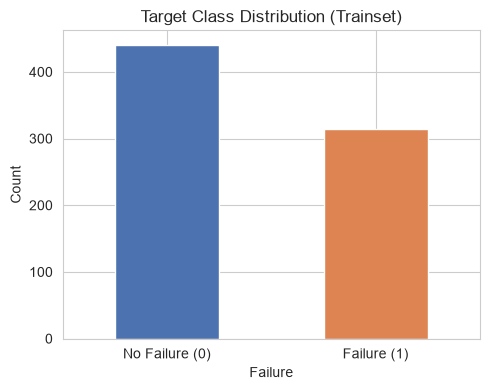

In [32]:
FIGURES_DIR = Path('figures/')
fig, ax = plt.subplots(figsize=(5, 4))
y_train.value_counts().sort_index().plot(kind="bar", color=["#4C72B0", "#DD8452"], ax=ax)
ax.set_xticklabels(["No Failure (0)", "Failure (1)"], rotation=0)
ax.set_ylabel("Count")
ax.set_title("Target Class Distribution (Trainset)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_balance.png", dpi=120)
plt.show()

The classes are moderately imbalanced (roughly 58% / 42%) — not extreme,
but enough that plain accuracy would be a misleading metric on its own. Every
model below is trained with class weighting and evaluated with precision,
recall, F1, ROC-AUC, and PR-AUC (average precision), not accuracy alone.

### 5.2 Feature distributions

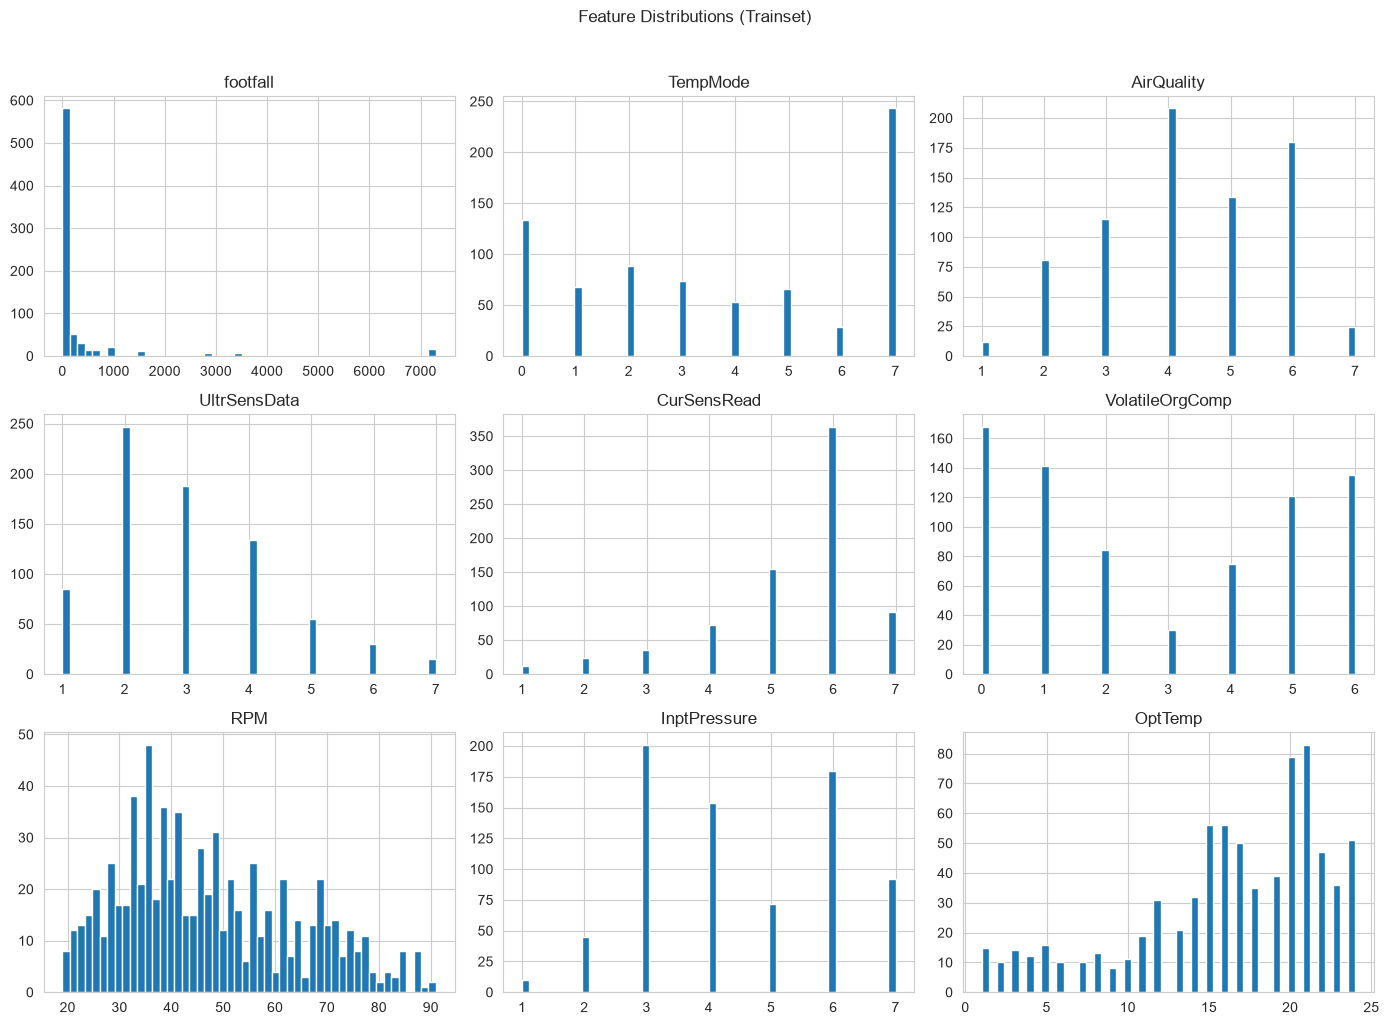

In [33]:
sensor_data_train = X_train.copy()
sensor_data_train.hist(bins=50, figsize=(14, 10))
plt.suptitle("Feature Distributions (Trainset)", y=1.02)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_histograms.png", dpi=120, bbox_inches="tight")
plt.show()

`footfall` is heavily right-skewed (a small number of very high readings) —
this is addressed later with a log transform during feature engineering.

### 5.3 Correlation with the target class

Failure            1.000000
VolatileOrgComp    0.791634
AirQuality         0.578732
OptTemp            0.204142
InptPressure       0.094821
RPM                0.036910
CurSensRead        0.013607
TempMode          -0.020991
footfall          -0.100819
UltrSensData      -0.481898
Name: Failure, dtype: float64


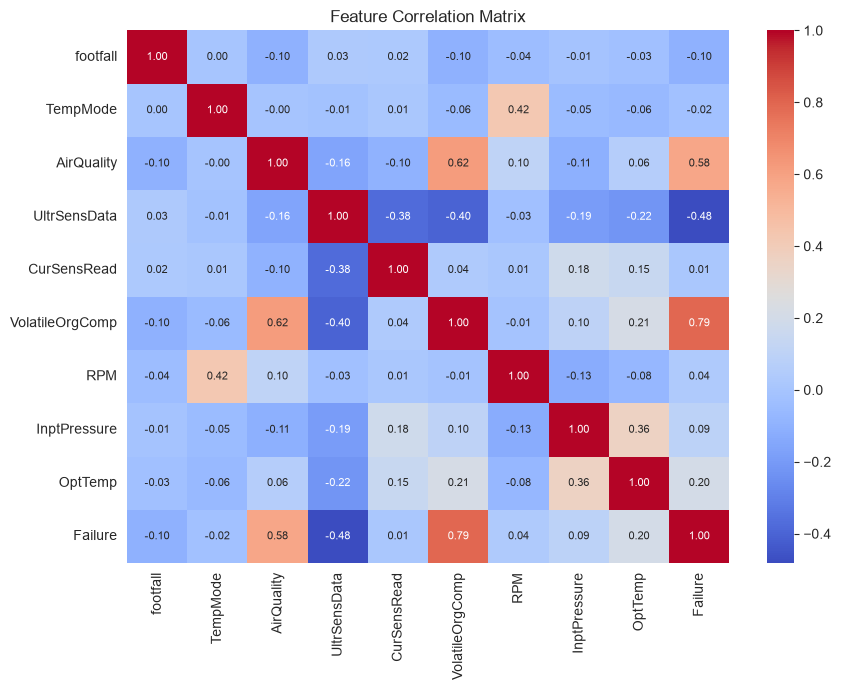

In [34]:
train_with_target = X_train.copy()
train_with_target["Failure"] = y_train.values
corr_matrix = train_with_target.corr()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, cmap="coolwarm", annot=True, fmt=".2f",
            annot_kws={"size": 8}, linecolor="lightgrey", ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "correlation_heatmap.png", dpi=120, bbox_inches="tight")
# plt.show()

print(corr_matrix["Failure"].sort_values(ascending=False))

`VolatileOrgComp` and `AirQuality` show the strongest raw correlation with `Failure`, while `UltrSensData`
correlates negatively.

This motivates the interaction features built in the next section.

### 5.4 Sensor Readings by Failure Status

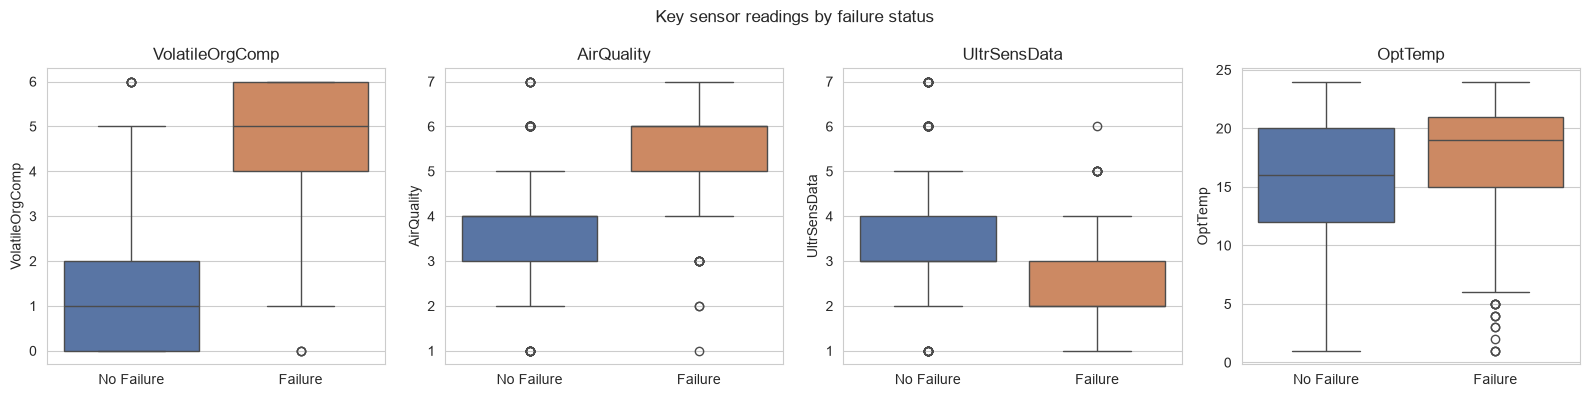

In [35]:
key_features = ["VolatileOrgComp", "AirQuality", "UltrSensData", "OptTemp"]
fig, axes = plt.subplots(1, len(key_features), figsize=(16, 4))
for ax, feature in zip(axes, key_features):
    sns.boxplot(x=y_train.values, y=X_train[feature], ax=ax, hue=y_train.values,
                palette={0: "#4C72B0", 1: "#DD8452"}, legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["No Failure", "Failure"])
    ax.set_xlabel("")
    ax.set_title(feature)
plt.suptitle("Key sensor readings by failure status")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "boxplots_by_class.png", dpi=120, bbox_inches="tight")

## 6. Feature Engineering

Three domain-informed interaction features, plus a log transform for the
skewed `footfall` reading:

- **`inv_UltrSensData`** — inverse of the ultrasonic sensor reading. `UltrSensData` correlates
  negatively with failure, so its inverse should correlate positively and may
  be easier for linear models to exploit.
- **`environmental_stress`** — `VolatileOrgComp * AirQuality`, a combined measure of air-quality
  stress.
- **`VOC-to-Ultrasonic`** —  VolatileOrgComp has the highest positive correlation with failure ($0.79$), while UltrSensData has the strongest negative correlation with failure ($-0.48$) (`VolatileOrgComp / (UltrSensData + epsilon)`).
- **`log_footfall`** — `log1p(footfall)` to reduce the influence of extreme
  outliers seen in section 5.2.

The transformer below is implemented as an sklearn-compatible class so it can
be embedded directly in the modeling pipeline: fit only on training data,
applied identically to the test set, with no risk of the two getting out of
sync.

In [38]:
class SensorFeatureEngineer(BaseEstimator, TransformerMixin):
    """Adds domain-informed interaction features to the raw sensor readings."""

    def __init__(self, eps=1e-5):
        self.eps = eps

    def fit(self, X, y=None):
        X = check_array(X)
        return self

    def transform(self, X):        
        X = X.copy()        
        X["Environmental_Stress"] = X["VolatileOrgComp"] * X["AirQuality"]
        X["VOC-to-USS"] = X["VolatileOrgComp"] / (X["UltrSensData"] + self.eps)
        X["log_footfall"] = np.log1p(X["footfall"])
        return X

    def get_feature_names_out(self, input_features=None):
        base = list(input_features) if input_features is not None else []
        return np.array(base + ["Environmental_Stress",
                                 "VOC-to-USS", "log_footfall"])

In [39]:
# Sanity check: confirm the engineered features actually add signal
ft_eng_obj = SensorFeatureEngineer()
X_train_engineered = ft_eng_obj.fit_transform(X_train)
Sample = X_train_engineered.copy()
Sample["Failure"] = y_train.values
print(Sample.corr()["Failure"].sort_values(ascending=False))

Failure                 1.000000
Environmental_Stress    0.797081
VolatileOrgComp         0.791634
VOC-to-USS              0.733865
AirQuality              0.578732
OptTemp                 0.204142
InptPressure            0.094821
RPM                     0.036910
CurSensRead             0.013607
TempMode               -0.020991
footfall               -0.100819
log_footfall           -0.191679
UltrSensData           -0.481898
Name: Failure, dtype: float64


**Environmental_Stress** correlates with the target class more strongly than any
raw feature, and **VOC-to-USS** also outperforms 'AirQuality' —
both are worth keeping. **log_footfall** indicates also an improvement of ($0.1$) in compare to its raw feature

## 7. Modeling Pipelines

Each candidate model is wrapped in a `Pipeline` that applies the feature
engineering step (and scaling, where relevant) before the classifier. This
guarantees the exact same transformation is applied to training and test
data, fit only once on the training set.

- Logistic Regression and SVC need scaled inputs.
- Random Forest and XGBoost are scale-invariant, so scaling is skipped for
  them.

All models use class weighting to counter the moderate class imbalance
observed above.

In [40]:
def build_pipeline(model, scale):
    steps = [("feature_engineering", SensorFeatureEngineer())]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("classifier", model))
    return Pipeline(steps)

class_ratio = (y_train == 0).sum() / (y_train == 1).sum()

candidates = {
    "Logistic Regression": (
        LogisticRegression(max_iter=1000, class_weight="balanced",
                           random_state=RANDOM_STATE),
        True,  # Requires scaling
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                               class_weight="balanced", random_state=RANDOM_STATE,
                               n_jobs=-1),
        False, # Tree-based model, no scaling needed
    ),
    "XGBoost": (
        XGBClassifier(n_estimators=300, learning_rate=0.09, max_depth=6,
                      subsample=0.8, colsample_bytree=0.8,
                      scale_pos_weight=class_ratio, random_state=RANDOM_STATE,
                      n_jobs=-1, eval_metric="logloss"),
        False, # Tree-based model, no scaling needed
    ),
    "CatBoost": (
        CatBoostClassifier(iterations=300, learning_rate=0.09, depth=6,
                           auto_class_weights='Balanced', random_seed=RANDOM_STATE,
                           verbose=0),
        False, # Tree-based model, no scaling needed
    ),
}

## 8. Cross-Validated Model Comparison

5-fold stratified cross-validation on the training set, scored on accuracy,
precision, recall, F1, ROC-AUC, and average precision (PR-AUC). Under class
imbalance, **average precision is the primary metric** used to rank models —
it's more sensitive to how well the model handles the minority (failure)
class than accuracy or ROC-AUC.

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

fitted_pipelines = {}
comparison_rows = []

for name, (model, scale) in candidates.items():
    pipe = build_pipeline(model, scale)
    fitted_pipelines[name] = pipe
    cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    row = {"Model": name}
    row.update({metric: cv_results[f"test_{metric}"].mean() for metric in scoring})
    comparison_rows.append(row)

results_df = pd.DataFrame(comparison_rows).sort_values("average_precision", ascending=False)
results_df.round(3)

,Model,accuracy,precision,recall,f1,roc_auc,average_precision
0,Logistic Regression,0.902,0.872,0.898,0.883,0.965,0.957
1,Random Forest,0.911,0.886,0.905,0.893,0.962,0.957
3,CatBoost,0.901,0.878,0.885,0.880,0.959,0.952
2,XGBoost,0.895,0.874,0.876,0.873,0.955,0.947


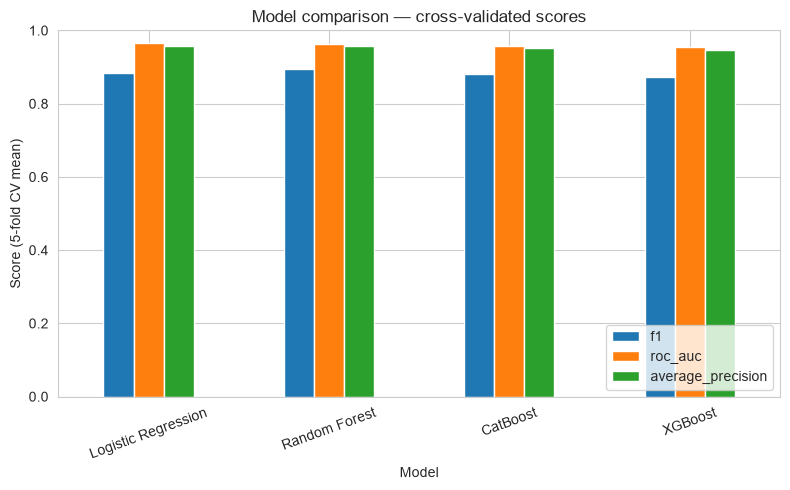

In [42]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_df = results_df.set_index("Model")[["f1", "roc_auc", "average_precision"]]
plot_df.plot(kind="bar", ax=ax)
ax.set_ylabel("Score (5-fold CV mean)")
ax.set_title("Model comparison — cross-validated scores")
ax.set_ylim(0, 1)
ax.legend(loc="lower right")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=120)

## 9. Hyperparameter Tuning

The top 2 models from the comparison above are tuned with
`RandomizedSearchCV` (30 iterations, same 5-fold stratified CV, scored on
average precision).

In [43]:
top_2_models = results_df["Model"].head(2).tolist()
print("Tuning:", top_2_models)

param_distributions = {
    "Logistic Regression": {
        "classifier__C": uniform(0.01, 10),
    },
    "Random Forest": {
        "classifier__n_estimators": randint(200, 700),
        "classifier__max_depth": [None, 5, 10, 15, 20, 30],
        "classifier__min_samples_leaf": randint(1, 10),
        "classifier__max_features": ["sqrt", "log2", None],
    }
}

tuning_rows = []
tuned_estimators = {}

for name in top_2_models:
    search = RandomizedSearchCV(
        fitted_pipelines[name],
        param_distributions=param_distributions[name],
        n_iter=30,
        scoring="average_precision",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    tuned_estimators[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best CV average precision": search.best_score_,
        "Best params": search.best_params_,
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values("Best CV average precision", ascending=False)
tuning_df

Tuning: ['Logistic Regression', 'Random Forest']


,Model,Best CV average precision,Best params
0,Logistic Regression,0.957584,{'classifier__C': 0.21584494295802448}
1,Random Forest,0.957409,"{'classifier__max_depth': 5, 'classifier__max_..."


In [44]:
best_model_name = tuning_df.iloc[0]["Model"]
final_pipeline = tuned_estimators[best_model_name]
print(f"Selected final model: {best_model_name}")

Selected final model: Logistic Regression


## 10. Decision Threshold Selection

The default 0.5 probability threshold is rarely optimal, especially with
class weighting in play. The threshold that maximizes F1 is selected using
**out-of-fold predictions on the training set only** (`cross_val_predict`) —
the test set is never used for this choice, so it stays a genuinely unbiased
final check.

In [45]:
oof_proba = cross_val_predict(
    final_pipeline, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

oof_precisions, oof_recalls, oof_thresholds = precision_recall_curve(y_train, oof_proba)
oof_f1_scores = 2 * oof_precisions * oof_recalls / (oof_precisions + oof_recalls + 1e-12)
best_idx = np.nanargmax(oof_f1_scores[:-1])
best_threshold = oof_thresholds[best_idx]

print(f"Selected threshold: {best_threshold:.3f}")
print(f"Out-of-fold F1 at this threshold: {oof_f1_scores[best_idx]:.3f}")

Selected threshold: 0.620
Out-of-fold F1 at this threshold: 0.891


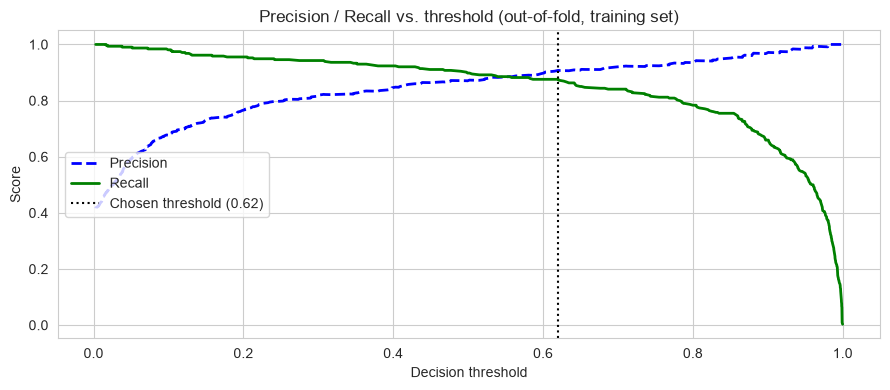

In [46]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(oof_thresholds, oof_precisions[:-1], "b--", label="Precision", linewidth=2)
ax.plot(oof_thresholds, oof_recalls[:-1], "g-", label="Recall", linewidth=2)
ax.axvline(best_threshold, color="k", linestyle=":", label=f"Chosen threshold ({best_threshold:.2f})")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Score")
ax.set_title("Precision / Recall vs. threshold (out-of-fold, training set)")
ax.legend(loc="center left")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "threshold_selection.png", dpi=120)
plt.show()

## 11. Final Model: Fit and Held-Out Test Evaluation

The tuned pipeline is fit once on the **entire training set** and evaluated
**once** on the held-out test set — the first and only time the test set is
used in this notebook.

In [47]:
final_pipeline.fit(X_train, y_train)

y_test_proba = final_pipeline.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= best_threshold).astype(int)

print(classification_report(y_test, y_test_pred, target_names=["No Failure", "Failure"]))
print(f"Test average precision (PR-AUC): {average_precision_score(y_test, y_test_proba):.3f}")

              precision    recall  f1-score   support

  No Failure       0.93      0.95      0.94       110
     Failure       0.93      0.90      0.92        79

    accuracy                           0.93       189
   macro avg       0.93      0.93      0.93       189
weighted avg       0.93      0.93      0.93       189

Test average precision (PR-AUC): 0.953


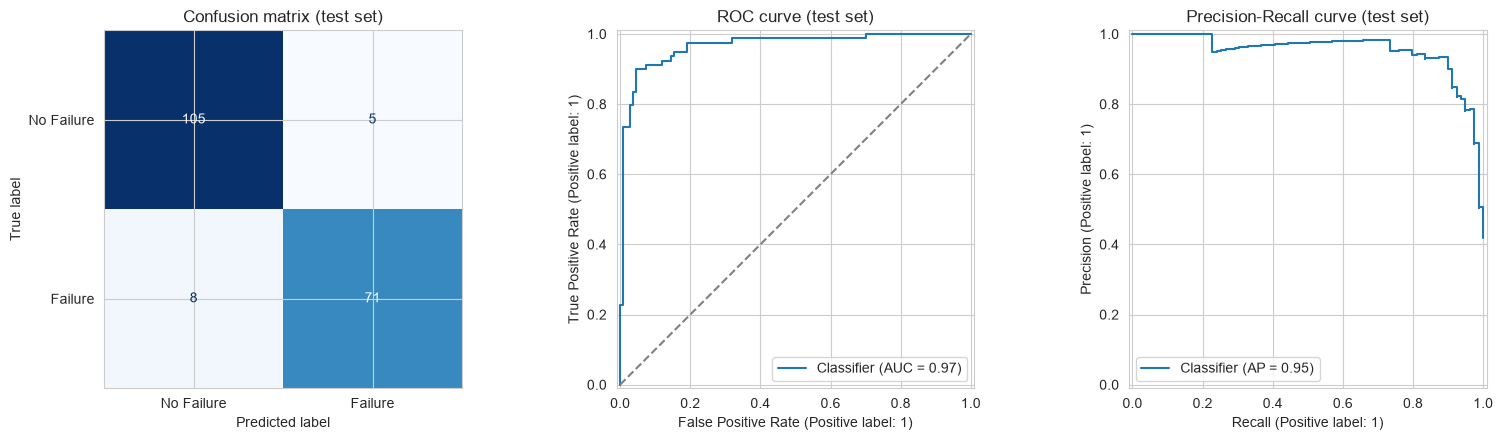

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, display_labels=["No Failure", "Failure"],
    cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion matrix (test set)")

RocCurveDisplay.from_predictions(y_test, y_test_proba, ax=axes[1])
axes[1].set_title("ROC curve (test set)")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")

PrecisionRecallDisplay.from_predictions(y_test, y_test_proba, ax=axes[2])
axes[2].set_title("Precision-Recall curve (test set)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "test_set_evaluation.png", dpi=120, bbox_inches="tight")
plt.show()

## 12. Model Interpretation

Feature importance (tree-based models) or standardized coefficients (linear
models) for the final chosen model.

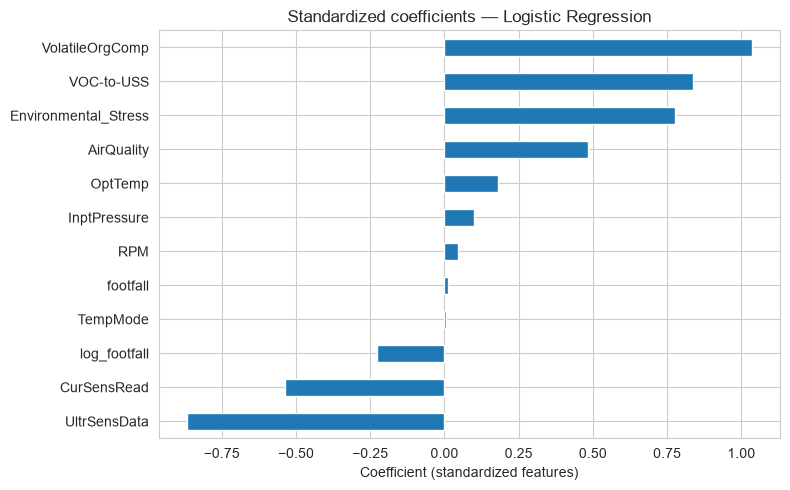

In [49]:
classifier = final_pipeline.named_steps["classifier"]
feature_names = final_pipeline.named_steps["feature_engineering"].get_feature_names_out(X_train.columns)

fig, ax = plt.subplots(figsize=(8, 5))

if hasattr(classifier, "feature_importances_"):
    importances = pd.Series(classifier.feature_importances_, index=feature_names)
    importances.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Feature importance — {best_model_name}")
    ax.set_xlabel("Importance")
elif hasattr(classifier, "coef_"):
    coefs = pd.Series(classifier.coef_[0], index=feature_names)
    coefs.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Standardized coefficients — {best_model_name}")
    ax.set_xlabel("Coefficient (standardized features)")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()

## 13. Model Persistence

The full pipeline (feature engineering + scaling + classifier) and the
chosen decision threshold are saved together, so the exact same
preprocessing is reproduced at inference time.

In [57]:
artifact = {
    "pipeline": final_pipeline,
    "threshold": best_threshold,
    "model_name": best_model_name,
}
joblib.dump(artifact, "models/LogisticRegressionModel.joblib")
print(f"Saved model artifact to {'models/machine_failure_model.joblib'}")

Saved model artifact to models/machine_failure_model.joblib


## 14. Conclusion

- The moderate class imbalance (58% / 42%) was handled through class
  weighting and evaluated with imbalance-aware metrics (F1, ROC-AUC,
  average precision) instead of relying on accuracy.
- Domain-informed interaction features — especially `environmental_stress`
  (`VOC * AQ`) — carried more predictive signal than any individual raw
  sensor reading.
- The final model was selected and tuned using only cross-validated
  performance on the training set; the test set was touched exactly once,
  for a final, unbiased performance estimate.
- The saved pipeline bundles feature engineering, scaling, the classifier,
  and the chosen decision threshold, so it can be dropped into a serving
  environment without re-deriving any of those steps by hand.